# 第二部分：Matching H0–H3 竞争机制——综合结果与边界

[README 与复现方法](README_zh.md) · [第一部分](../01_reproduction_2020/reproduction_results.ipynb) · [归档与命名](docs/ARCHIVE_AND_NAMING.md)

状态快照：2026-10-28。**全数据正式拟合和完整 PPC 已完成；可靠五折预测比较尚未完成；第三部分尚未正式分析。** 本文为当前结果入口，读取保存的汇总和图，无 MCMC、无输出目录覆盖。

## 研究问题 → 方法选择

Good-self−Bad-self 优势需要 log(v) 对比、dc 对比还是二者？H0 均固定为零，H1 仅目标 v 对比自由，H2 仅目标 dc 对比自由，H3 两者自由。零约束施加到每名被试，不只群体均值。其余层级结构、a/t/z、其他条件效应与观察规则保持一致。

42×600=25,200 事件：24,527 合法响应、649 超时、24 非法按键。上边界为 Match。Mismatch 三类标签关系采用零和 log 难度参照；对被试共享截止积分，截止代理来自原记录。新的 log(v) 对比不是历史 M4 原始尺度差 0.666。

## 诊断发现 → 方法调整

[行为诊断](matching_behavior_review.ipynb)发现口径差异、标签难度和快速反应结构；[模拟](matching_mechanism_simulation.ipynb)与[审查](matching_mechanism_audit.ipynb)表明旧参数代入、有限网格不能替代恢复。随后[观察模型日志](matching_observation_recovery.ipynb)建立一致的生成—估计过程并改进采样，保持先验和目标后验，未通过延长失败链或放宽门槛“制造”机制结论。

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / '01_reproduction_2020').is_dir()), None)
if ROOT is None:
    raise FileNotFoundError('Run inside the hu2020-ddm repository.')
pd.set_option('display.max_columns', 12)
pd.set_option('display.max_rows', 32)
pd.set_option('display.float_format', lambda x: f'{x:.5f}')
def table(path):
    return pd.read_csv(ROOT / path)
def show(path, width=1000):
    display(Image(filename=str(ROOT / path), width=width))


## 有限模拟恢复

32 个候选拟合全部通过采样诊断，但 H0–H3 各仅两份独立生成数据。这是特定参数与参照下的有限恢复，不能估计稳定恢复率/覆盖率，不能推广到所有效应范围或真实机制。图 II-1 的参数恢复与下表的修正预测比较回答不同问题。

修正模拟比较的 SE 为42名被试配对分数和的聚类标准误；gap>2 SE 仅作描述，不是确定机制的选择定理，精确重拟合 MCSE 另列。

In [2]:
recovery = table('02_reanalysis_2026/Output/hddm/matching/continuation_20261026/recovery_summary/mcmc_diagnostics.csv')
display(recovery)

,dataset,model,n_parameters,max_rhat,min_bulk_ess,min_tail_ess,n_rhat_failed,n_bulk_failed,n_tail_failed,finite
0,H0_r01,H0,1408,1.00317,1067.25512,1007.22849,0,0,0,True
1,H0_r01,H1,1452,1.00581,1146.34363,938.88123,0,0,0,True
2,H0_r01,H2,1452,1.00429,1112.84932,727.18776,0,0,0,True
3,H0_r01,H3,1496,1.00898,1054.88137,681.33046,0,0,0,True
4,H0_r02,H0,1408,1.00384,1013.88027,870.45213,0,0,0,True
5,H0_r02,H1,1452,1.00294,983.89653,750.67082,0,0,0,True
6,H0_r02,H2,1452,1.00467,975.85592,823.96710,0,0,0,True
7,H0_r02,H3,1496,1.00484,1056.59350,879.29966,0,0,0,True
8,H1_r01,H0,1408,1.00660,803.84615,755.48942,0,0,0,True
9,H1_r01,H1,1452,1.00604,702.63561,558.70325,0,0,0,True


### 图 II-1｜有限模拟目标参数恢复

比较已知生成目标与拟合后验；查看偏差和区间，不将仅两次重复的覆盖计数当作概率保证。

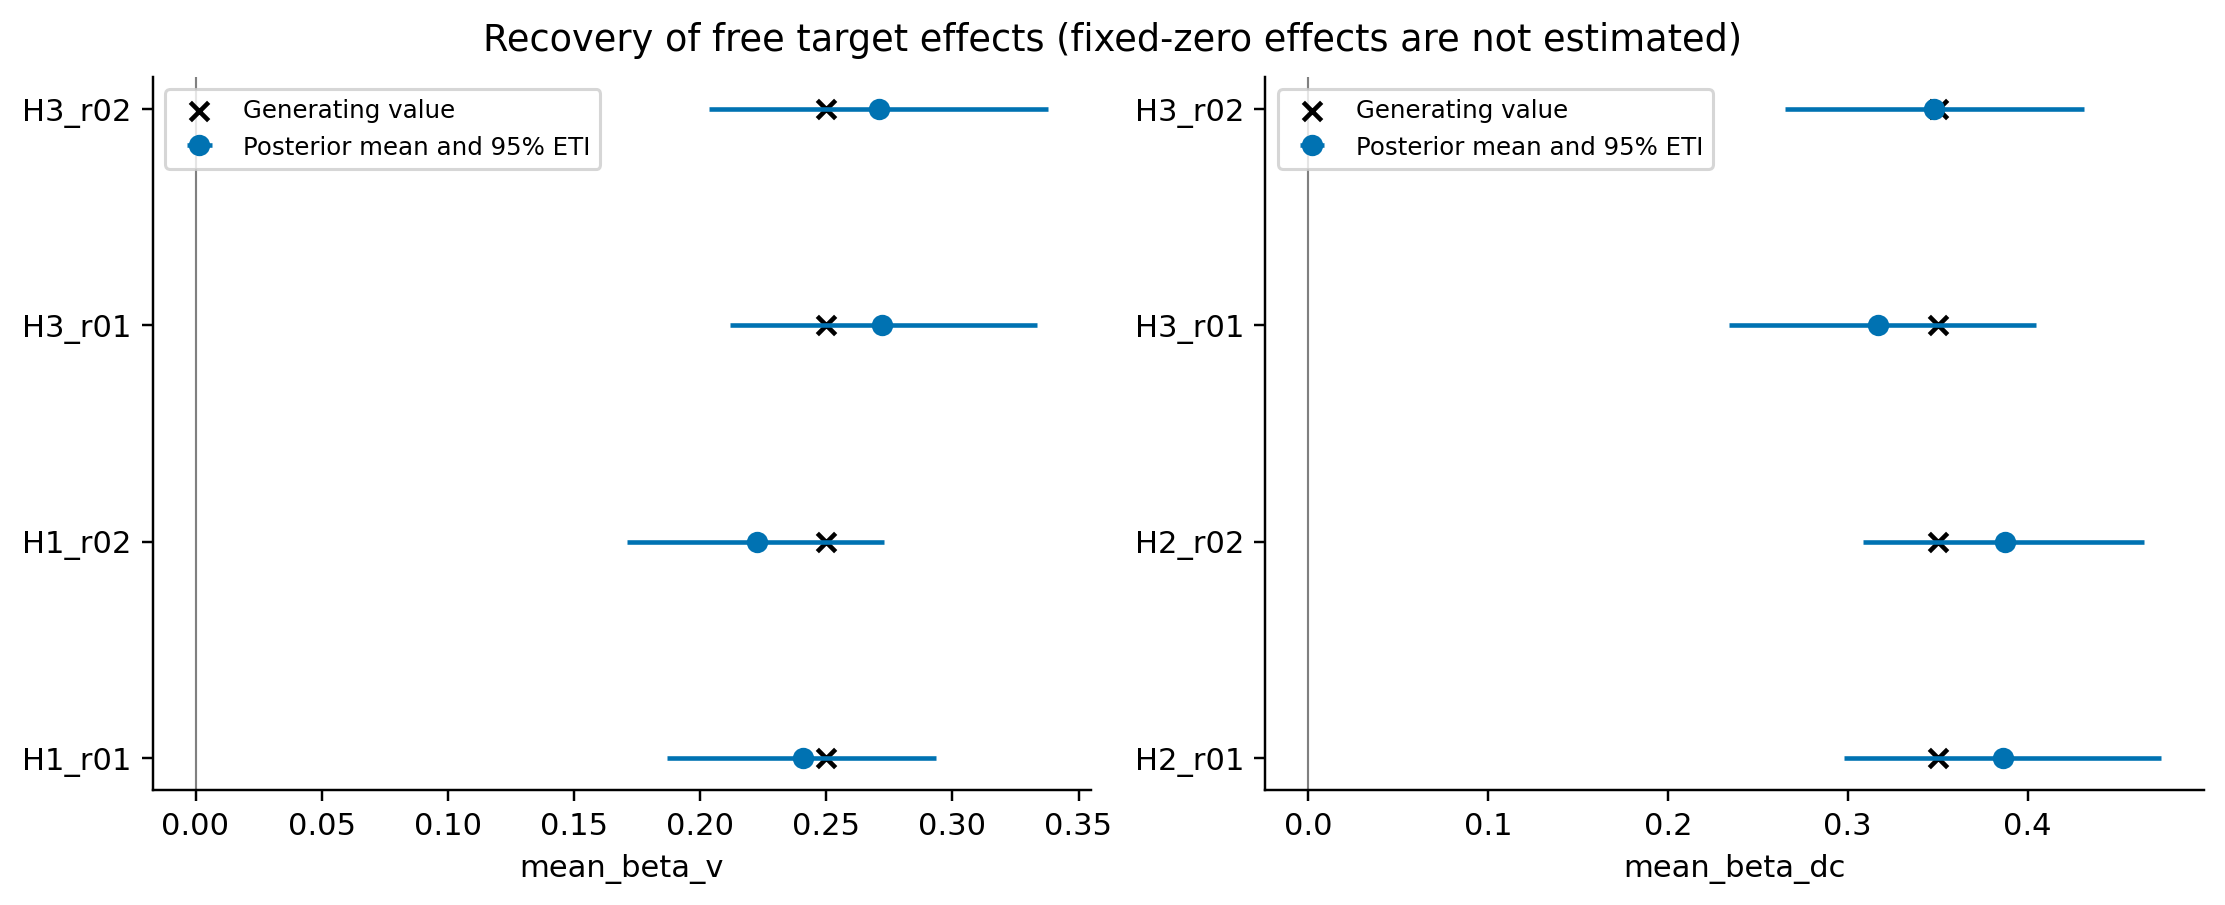

In [3]:
show('02_reanalysis_2026/Output/hddm/matching/continuation_20261026/recovery_summary/target_parameter_recovery.png')

## 真实数据：采样诊断与后验

全参数统一 R̂<1.01、bulk/tail ESS≥400，四链每链 8,000 保留样本。高 Pareto-k 提醒逐事件预测近似不可直接排名；收敛不等于模型充分。

In [4]:
display(table('02_reanalysis_2026/Output/hddm/matching/continuation_20261026/recovery_corrected/model_comparisons.csv'))

,dataset,comparison_reliable,numerical_maximum,runner_up,delta_to_runner_up,subject_cluster_se,status
0,H0_r01,True,H2,H0,1.33630,2.89252,ambiguous
1,H0_r02,True,H0,H1,1.08690,1.94616,ambiguous
2,H1_r01,True,H1,H3,0.29696,1.20060,ambiguous
3,H1_r02,True,H1,H3,0.77287,1.17469,ambiguous
4,H2_r01,True,H2,H3,0.82362,1.09971,ambiguous
5,H2_r02,True,H3,H2,2.87069,3.15975,ambiguous
6,H3_r01,True,H3,H1,29.63251,8.02391,gap_exceeds_2SE
7,H3_r02,True,H3,H1,35.82165,7.90685,gap_exceeds_2SE


In [5]:
diagnostics = table('02_reanalysis_2026/Output/hddm/matching/continuation_stage5_20261027/four_model_diagnostics.csv')
assert len(diagnostics)==4 and diagnostics.mcmc_pass.all()
assert (diagnostics.max_rhat<1.01).all() and (diagnostics[['min_bulk_ess','min_tail_ess']]>=400).all().all()
display(diagnostics)

,model,retained_per_chain,max_rhat,min_bulk_ess,min_tail_ess,mcmc_pass,high_pareto_k_events,max_pareto_k
0,H0,8000,1.00125,2792.58701,3382.51125,True,13,1.08705
1,H1,8000,1.00170,2993.59296,3738.87415,True,24,1.31177
2,H2,8000,1.00267,2351.01432,1620.84303,True,17,1.47662
3,H3,8000,1.00124,3094.94335,3445.15830,True,19,1.65529


### 图 II-2｜四模型目标后验

森林图为模型内后验及其区间；被固定为零的项不是自由估计。H3 两目标正向与特定参数化相容，不能证明它优于 H1/H2 或唯一心理机制。

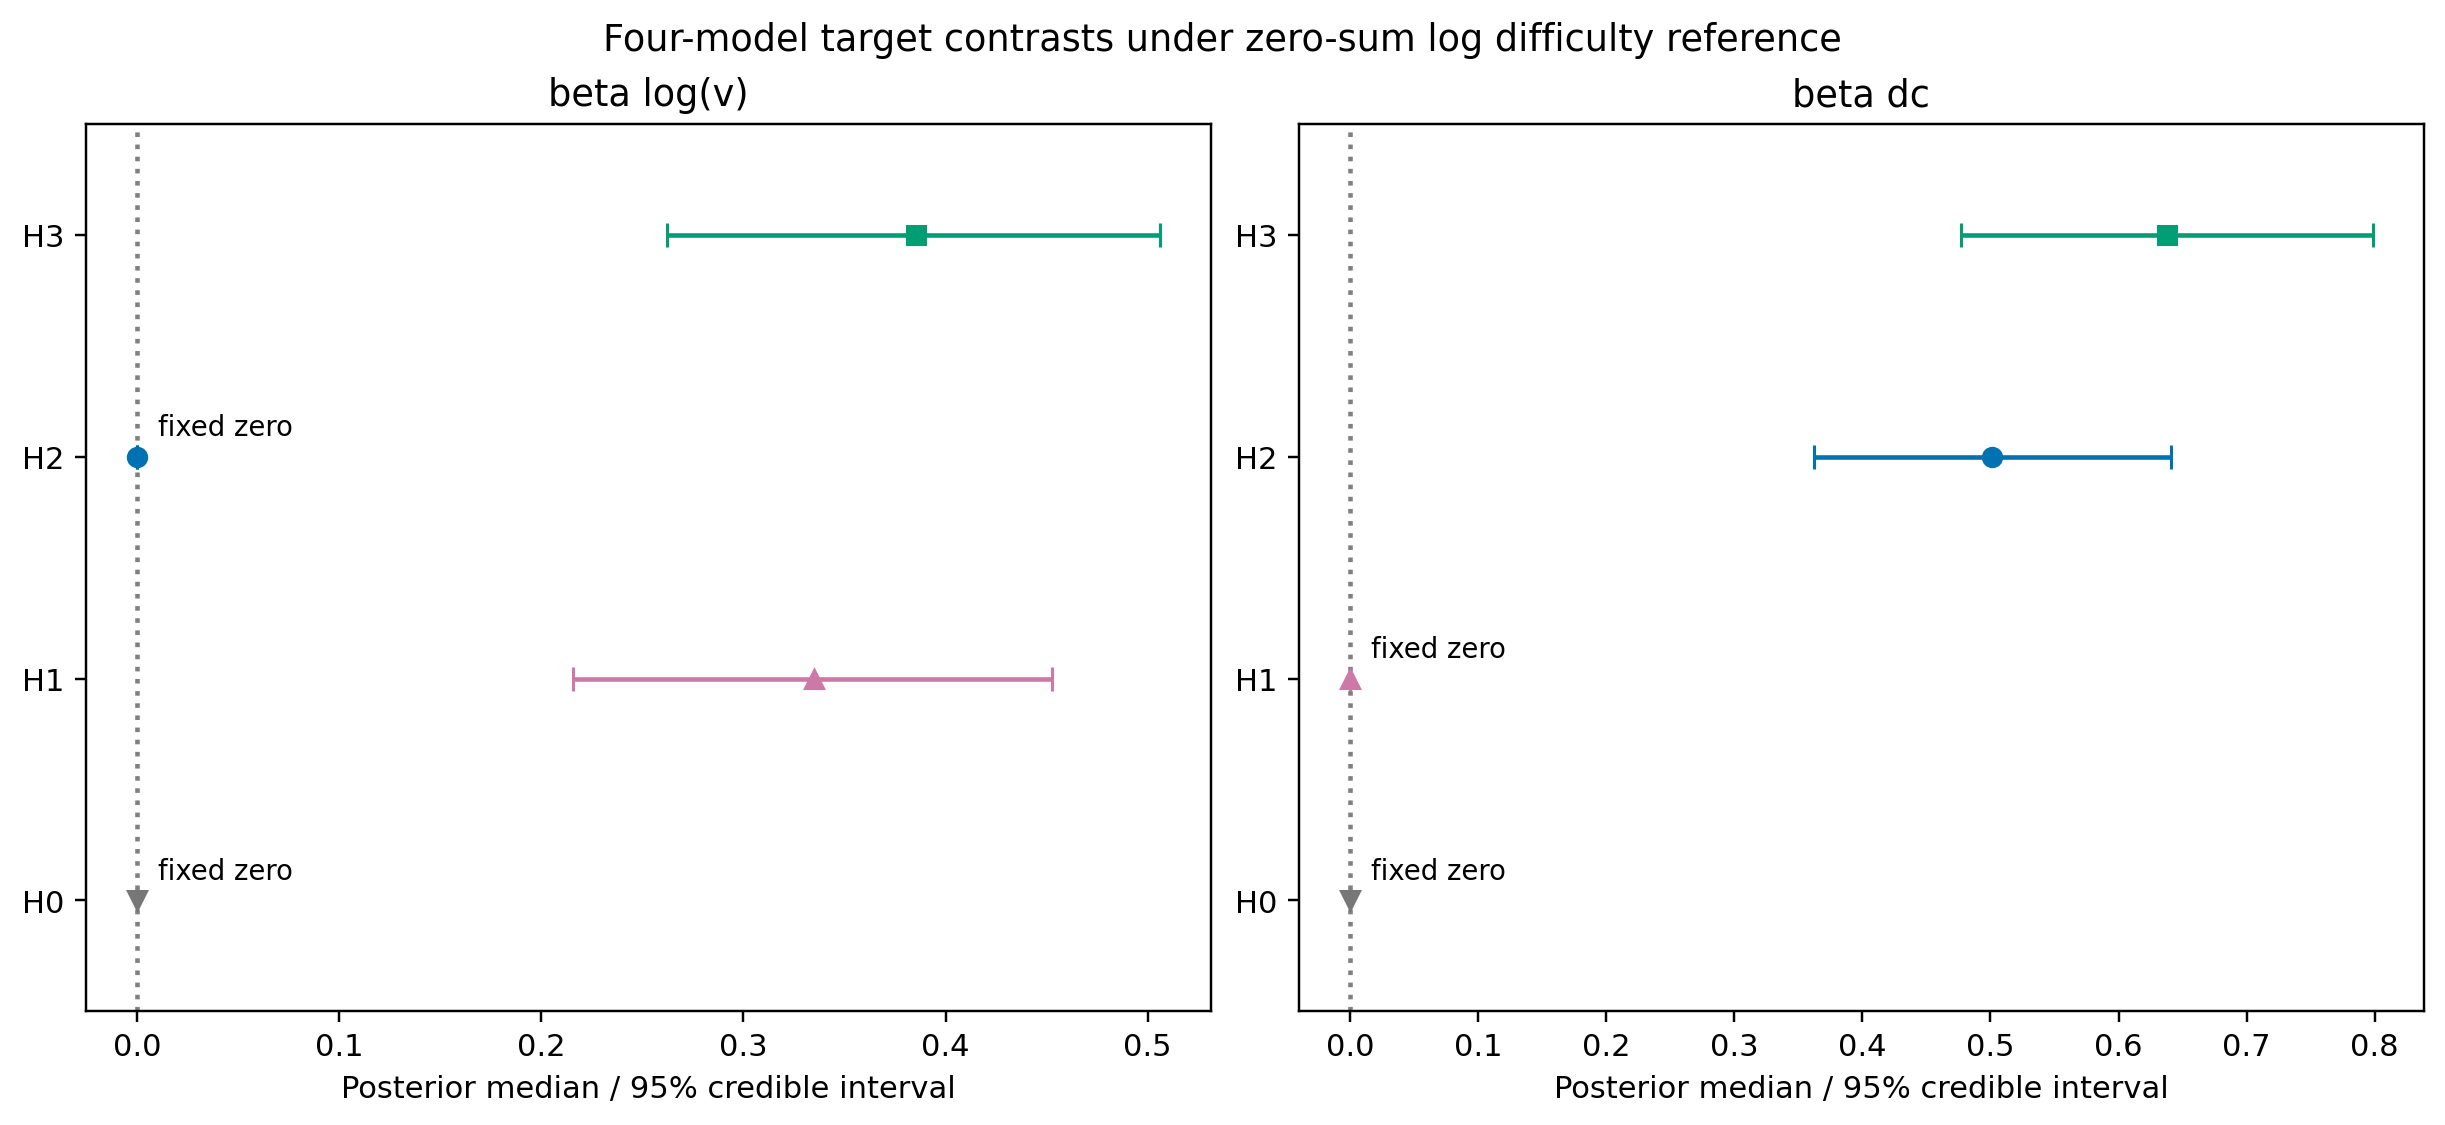

,parameter,mean,median,lower,upper,fixed_zero,model
0,mean_beta_v,0.00000,0.00000,0.00000,0.00000,True,H0
1,mean_beta_dc,0.00000,0.00000,0.00000,0.00000,True,H0
2,sd_beta_v,0.00000,0.00000,0.00000,0.00000,True,H0
3,sd_beta_dc,0.00000,0.00000,0.00000,0.00000,True,H0
4,contamination,0.04719,0.04713,0.04328,0.05146,False,H0
5,illegal_rate,0.00095,0.00094,0.00061,0.00136,False,H0
6,relation_coef1,-0.14674,-0.14683,-0.18611,-0.10824,False,H0
7,relation_coef2,-0.29560,-0.29560,-0.32675,-0.26418,False,H0
8,mean_beta_v,0.33468,0.33474,0.21575,0.45276,False,H1
9,mean_beta_dc,0.00000,0.00000,0.00000,0.00000,True,H1


In [6]:
show('02_reanalysis_2026/Output/hddm/matching/continuation_stage4_20261027/four_model_ppc/four_model_target_forest.png')
display(table('02_reanalysis_2026/Output/hddm/matching/continuation_stage4_20261027/four_model_ppc/four_model_key_parameter_summary.csv'))

## 结果：完整后验预测检验（PPC）

每模型四链各抽 50 个后验样本，共 200 个完整设计复本。合法选择/准确率以合法响应为分母，超时以全部事件为分母；95% 区间是逐统计量预测区间，不是同时区间。越界计数是描述性失配诊断，不是多重检验后的显著性计数。

In [7]:
misfit=table('02_reanalysis_2026/Output/hddm/matching/continuation_stage4_20261027/four_model_ppc/four_model_misfit_counts.csv')
key=misfit[misfit.metric.isin(['correct_mean_rt','timeout_rate'])]
assert len(key)==8 and key.outside.eq(8).all()
display(misfit)

,model,metric,groups,outside,median_bias_min,median_bias_max
0,H0,correct_mean_rt,8,8,-0.04571,0.03644
1,H0,error_mean_rt,8,5,-0.04253,0.03951
2,H0,timeout_rate,8,8,0.05683,0.08079
3,H0,accuracy_given_response,8,5,-0.01317,0.08549
4,H0,match_choice_given_response,8,5,-0.03037,0.08549
5,H0,illegal_rate,8,0,-0.00063,0.00095
6,H1,correct_mean_rt,8,8,-0.03991,0.02462
7,H1,error_mean_rt,8,4,-0.04036,0.04000
8,H1,timeout_rate,8,8,0.05175,0.08984
9,H1,accuracy_given_response,8,6,-0.02655,0.06420


### 图 II-3｜绝对拟合：准确率、RT、超时

四模型的正确 RT 均值和超时率均有 8/8 条件失配。即使参数采样稳定，这个共同不足仍限制模型族的心理解释。

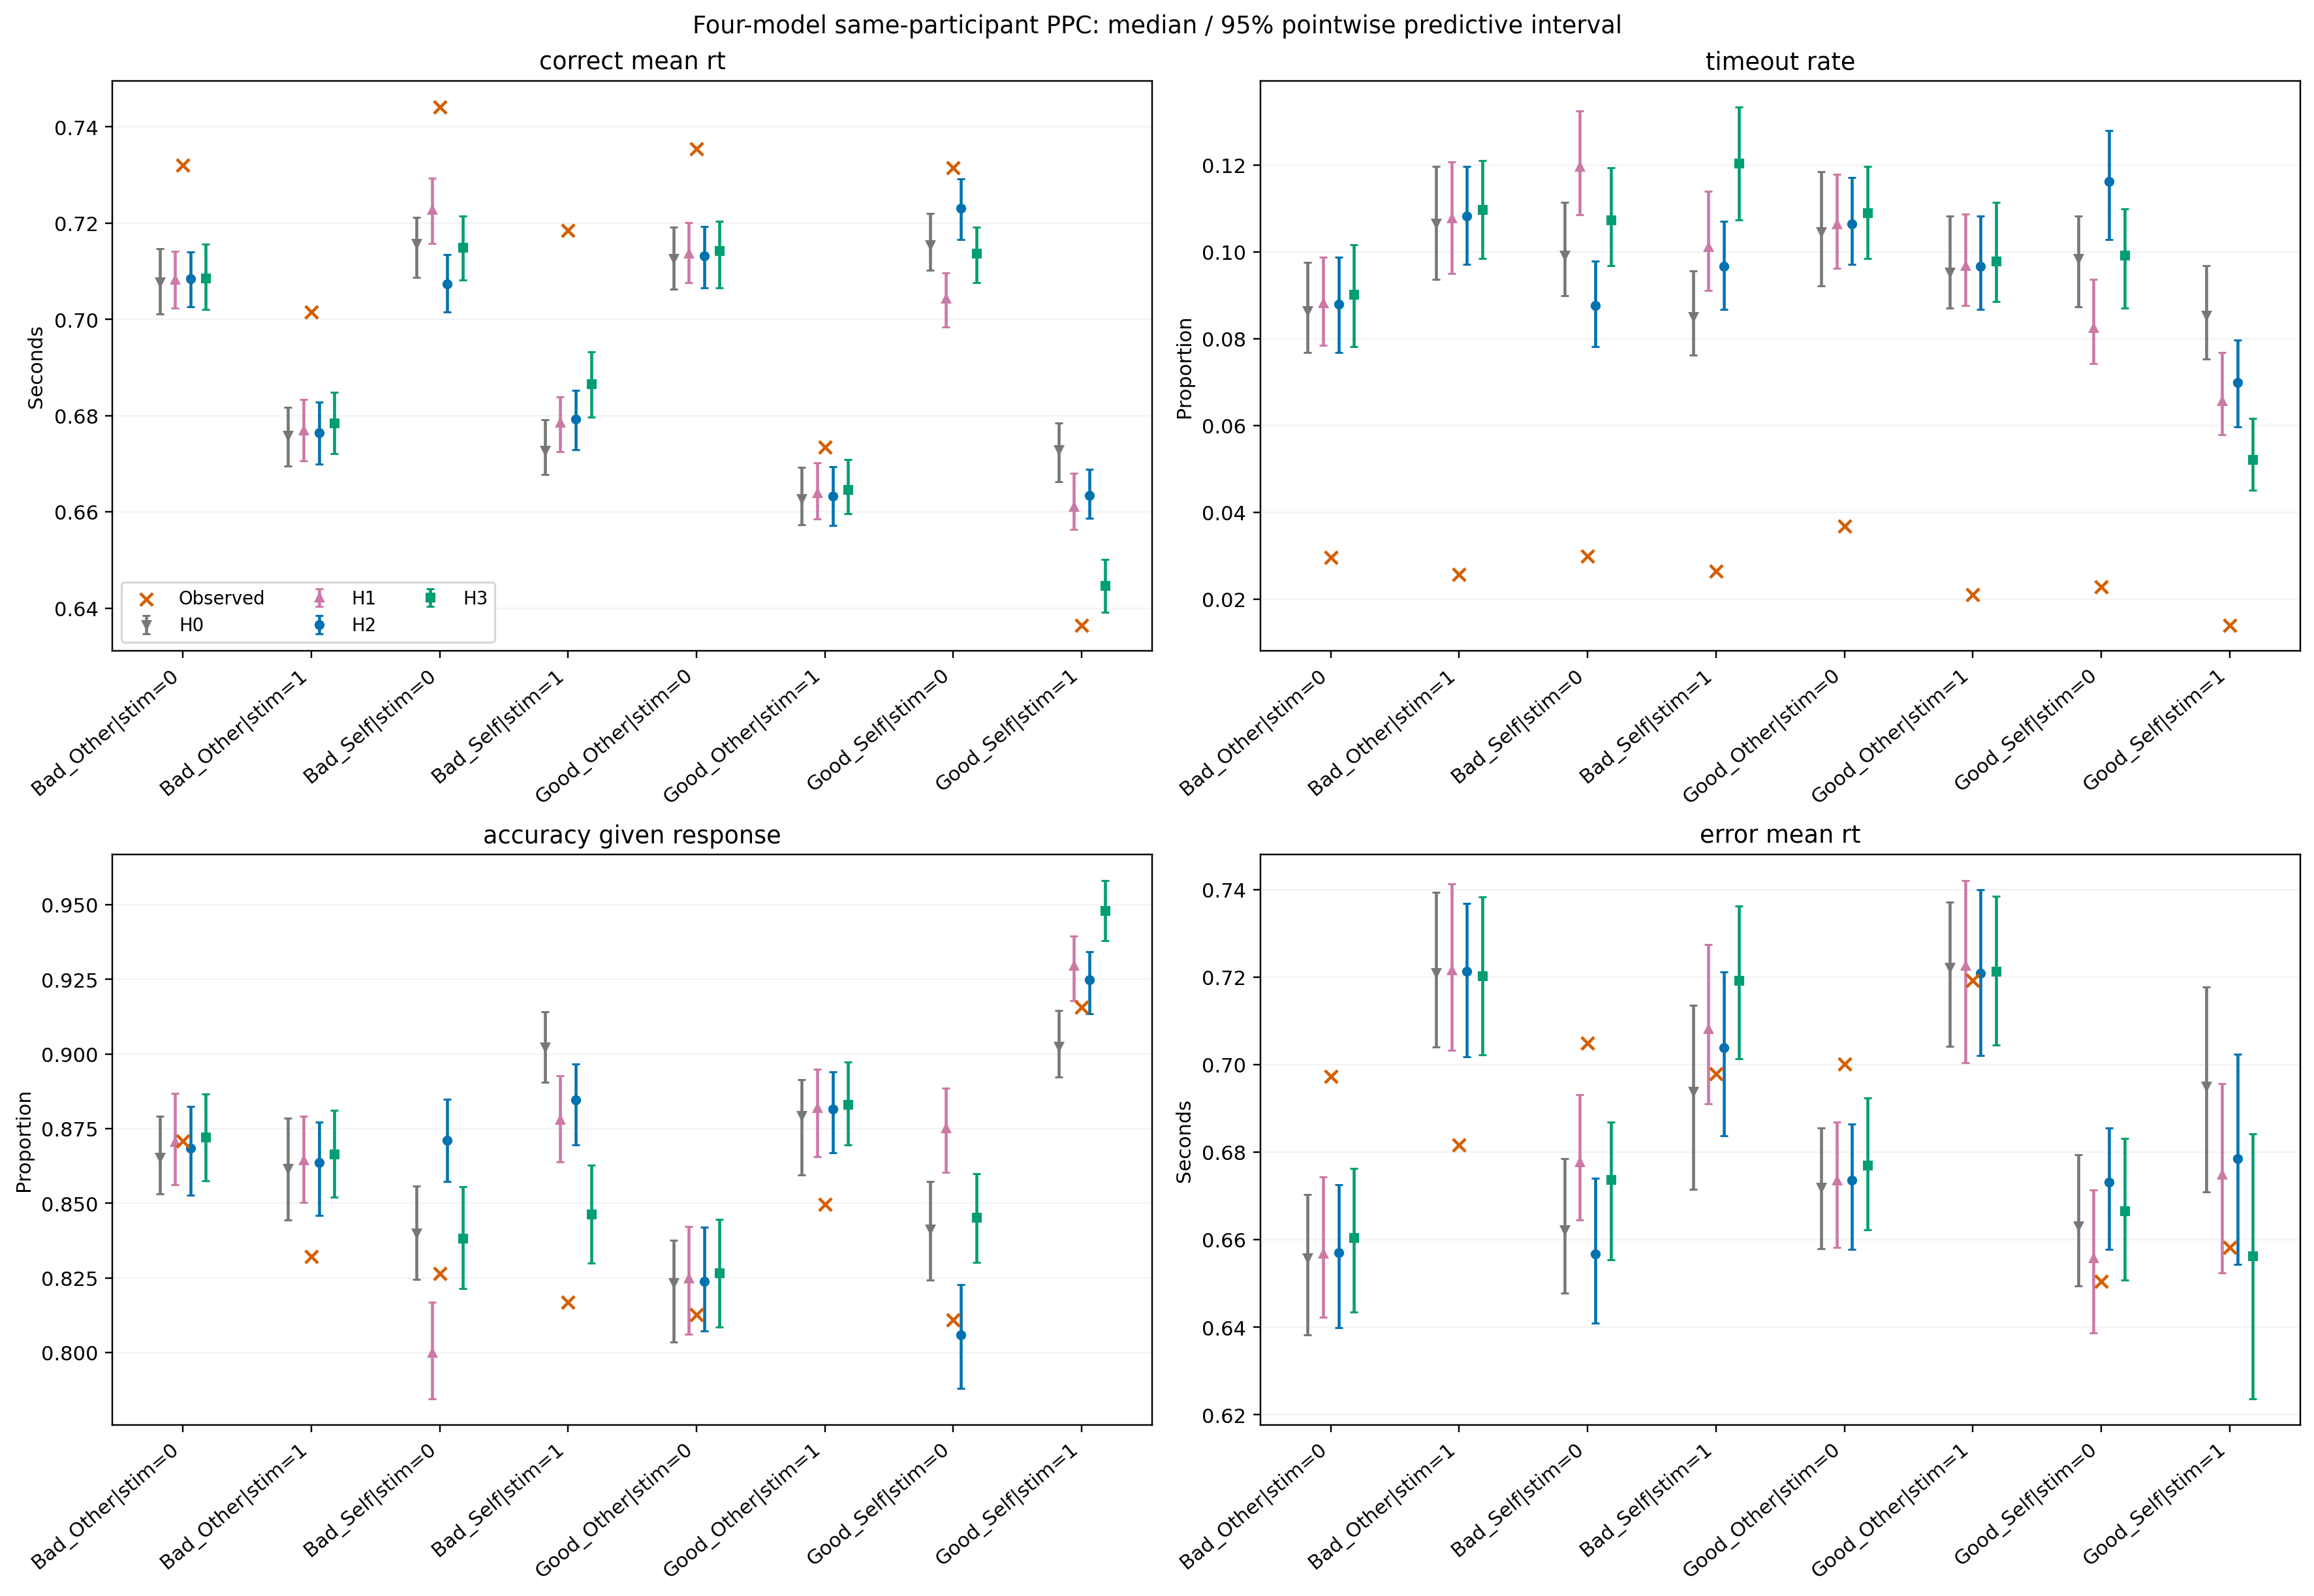

In [8]:
show('02_reanalysis_2026/Output/hddm/matching/continuation_stage4_20261027/four_model_ppc/four_model_absolute_fit_ppc.png')

### 图 II-4｜Good-self−Bad-self 行为对比

H3 改善部分整体准确率与 RT 差异，但不能同时解释全部特征。Match 正确 RT 差观测约 −82.9ms，H3 约 −43.2ms、H2 约 −15.8ms。此处是全事件模型的合法响应口径，不与第一部分 −82.56ms 直接视为同一统计。

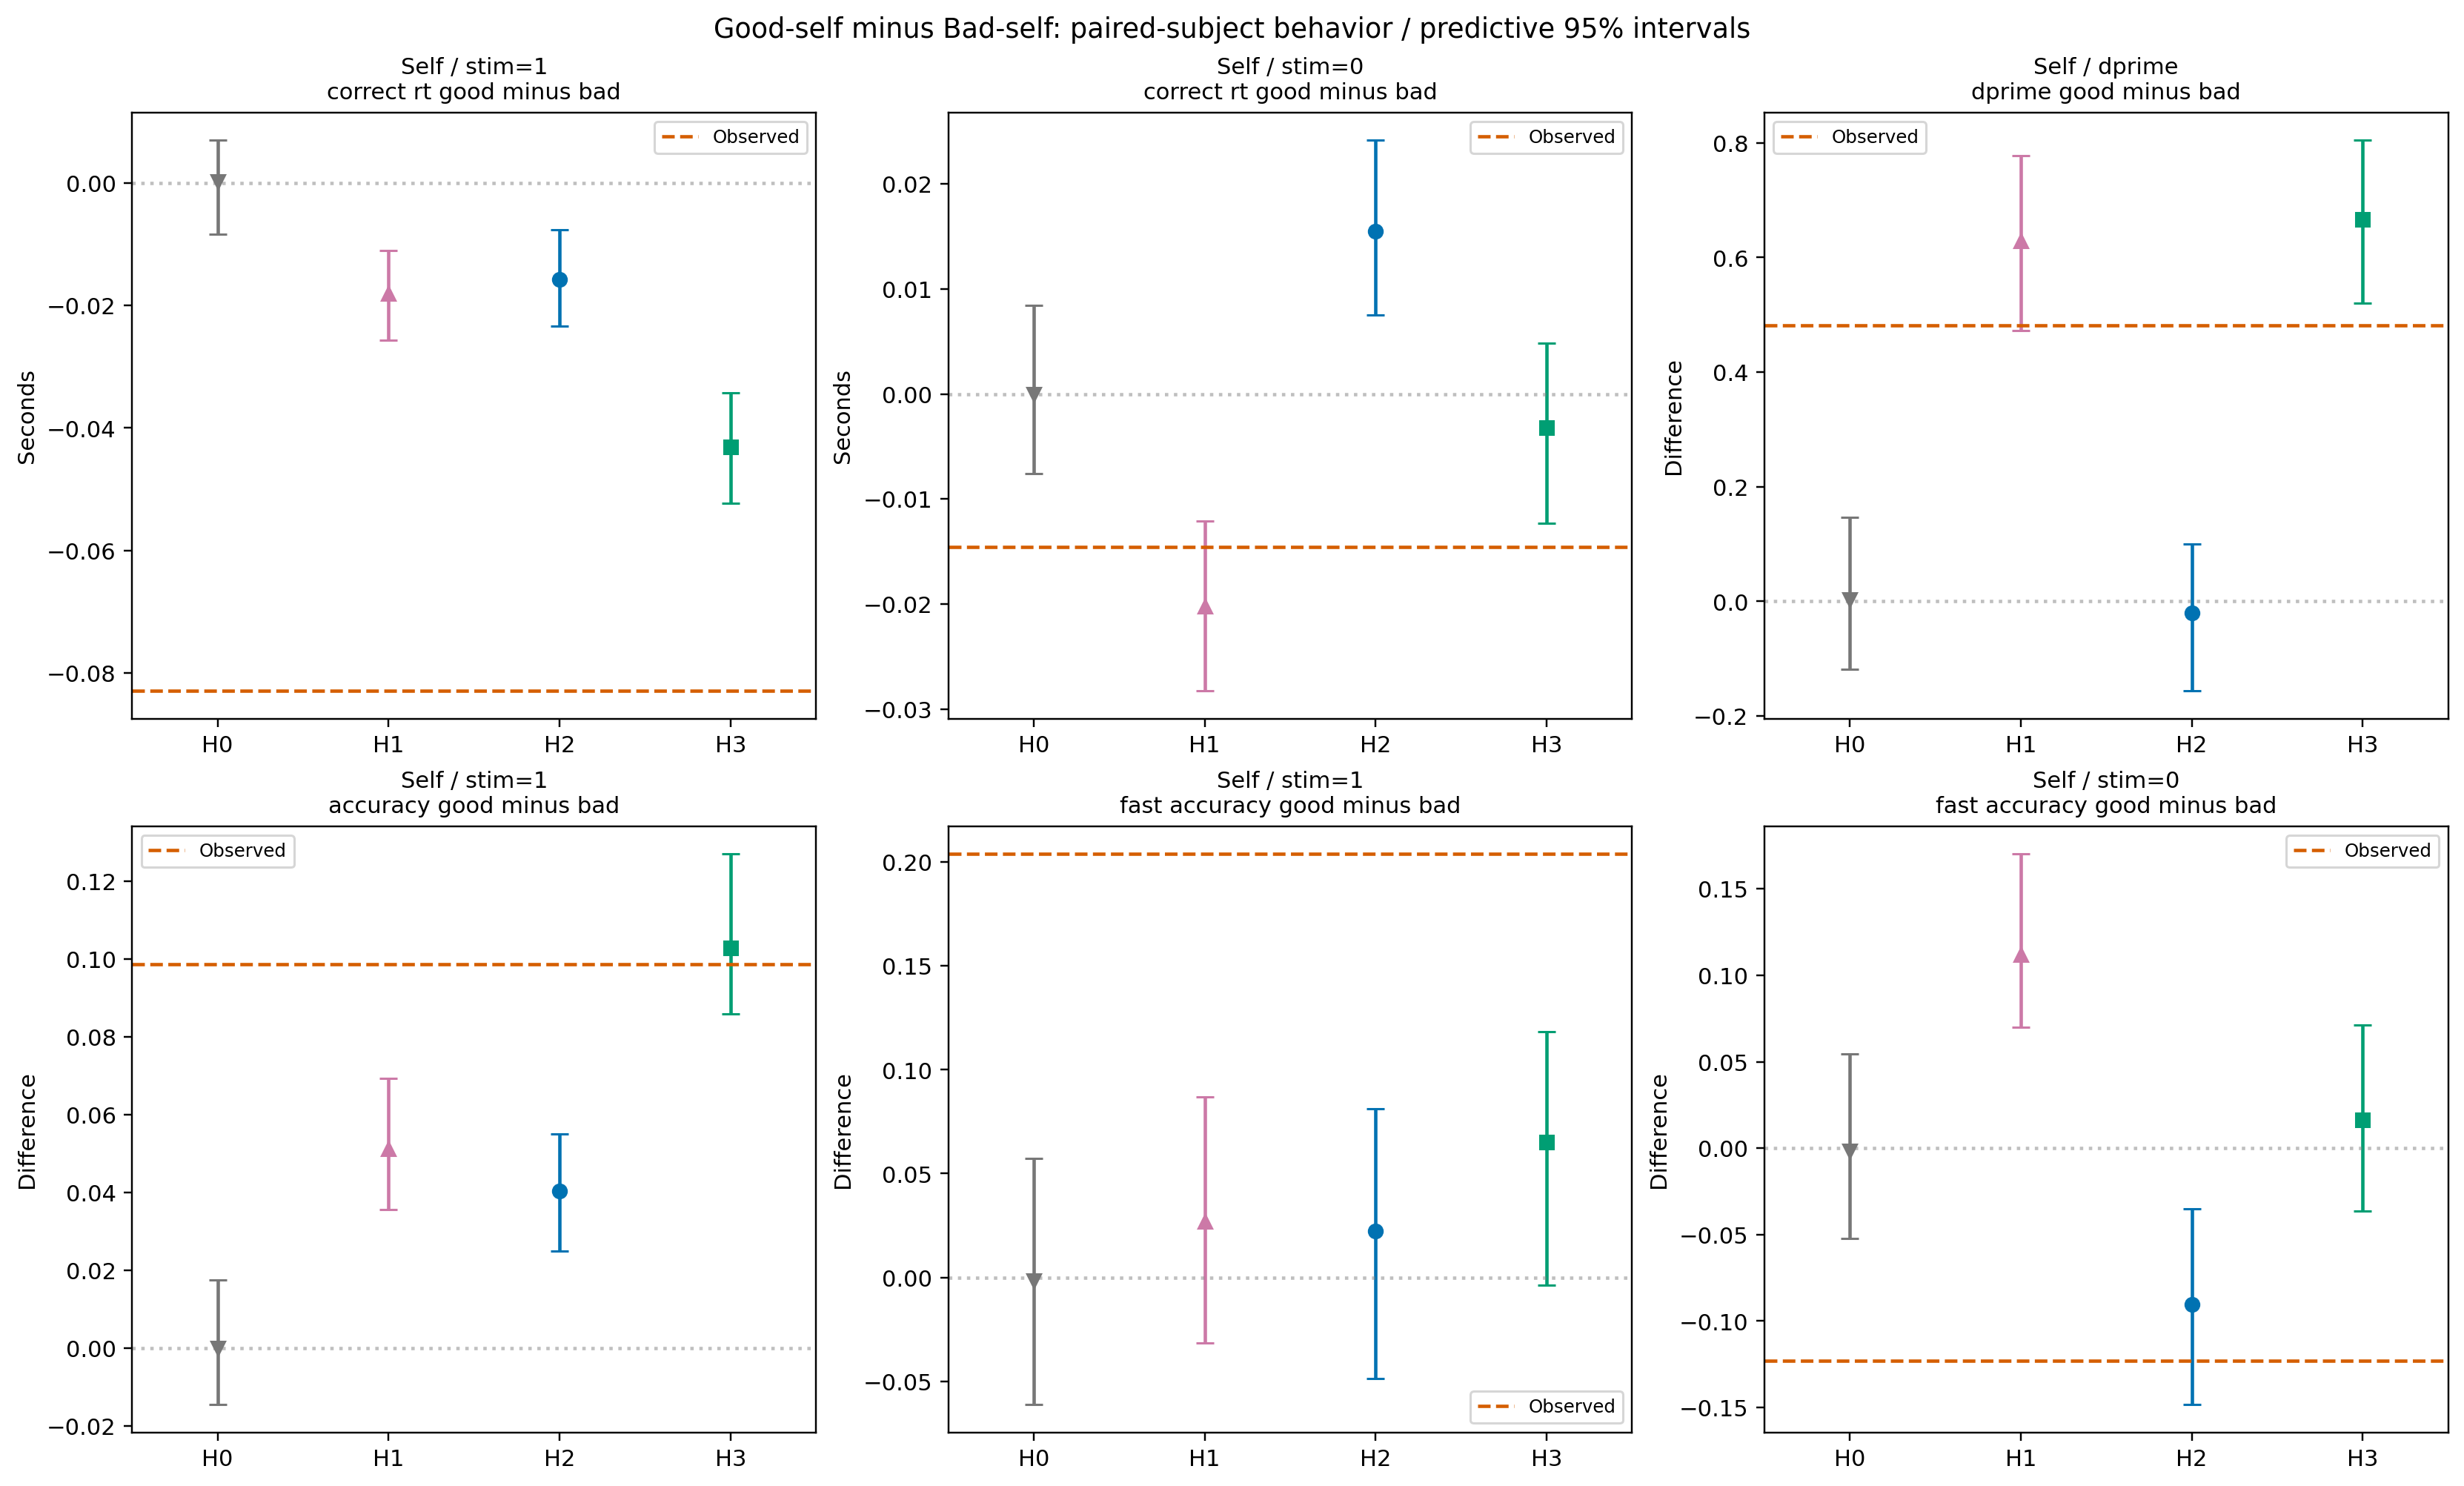

In [9]:
show('02_reanalysis_2026/Output/hddm/matching/continuation_stage4_20261027/four_model_ppc/four_model_target_behavior_ppc.png')

### 图 II-5｜快速反应形状

快速阈值和五分位边界由观测 Self 合并分布固定，区分 Match/Mismatch，并对所有复制一致使用。快速 Match 优势观测约 .204，四模型预测中位数约 −.002/.027/.022/.065，全部95%逐统计量预测区间未覆盖；H3仍低估。

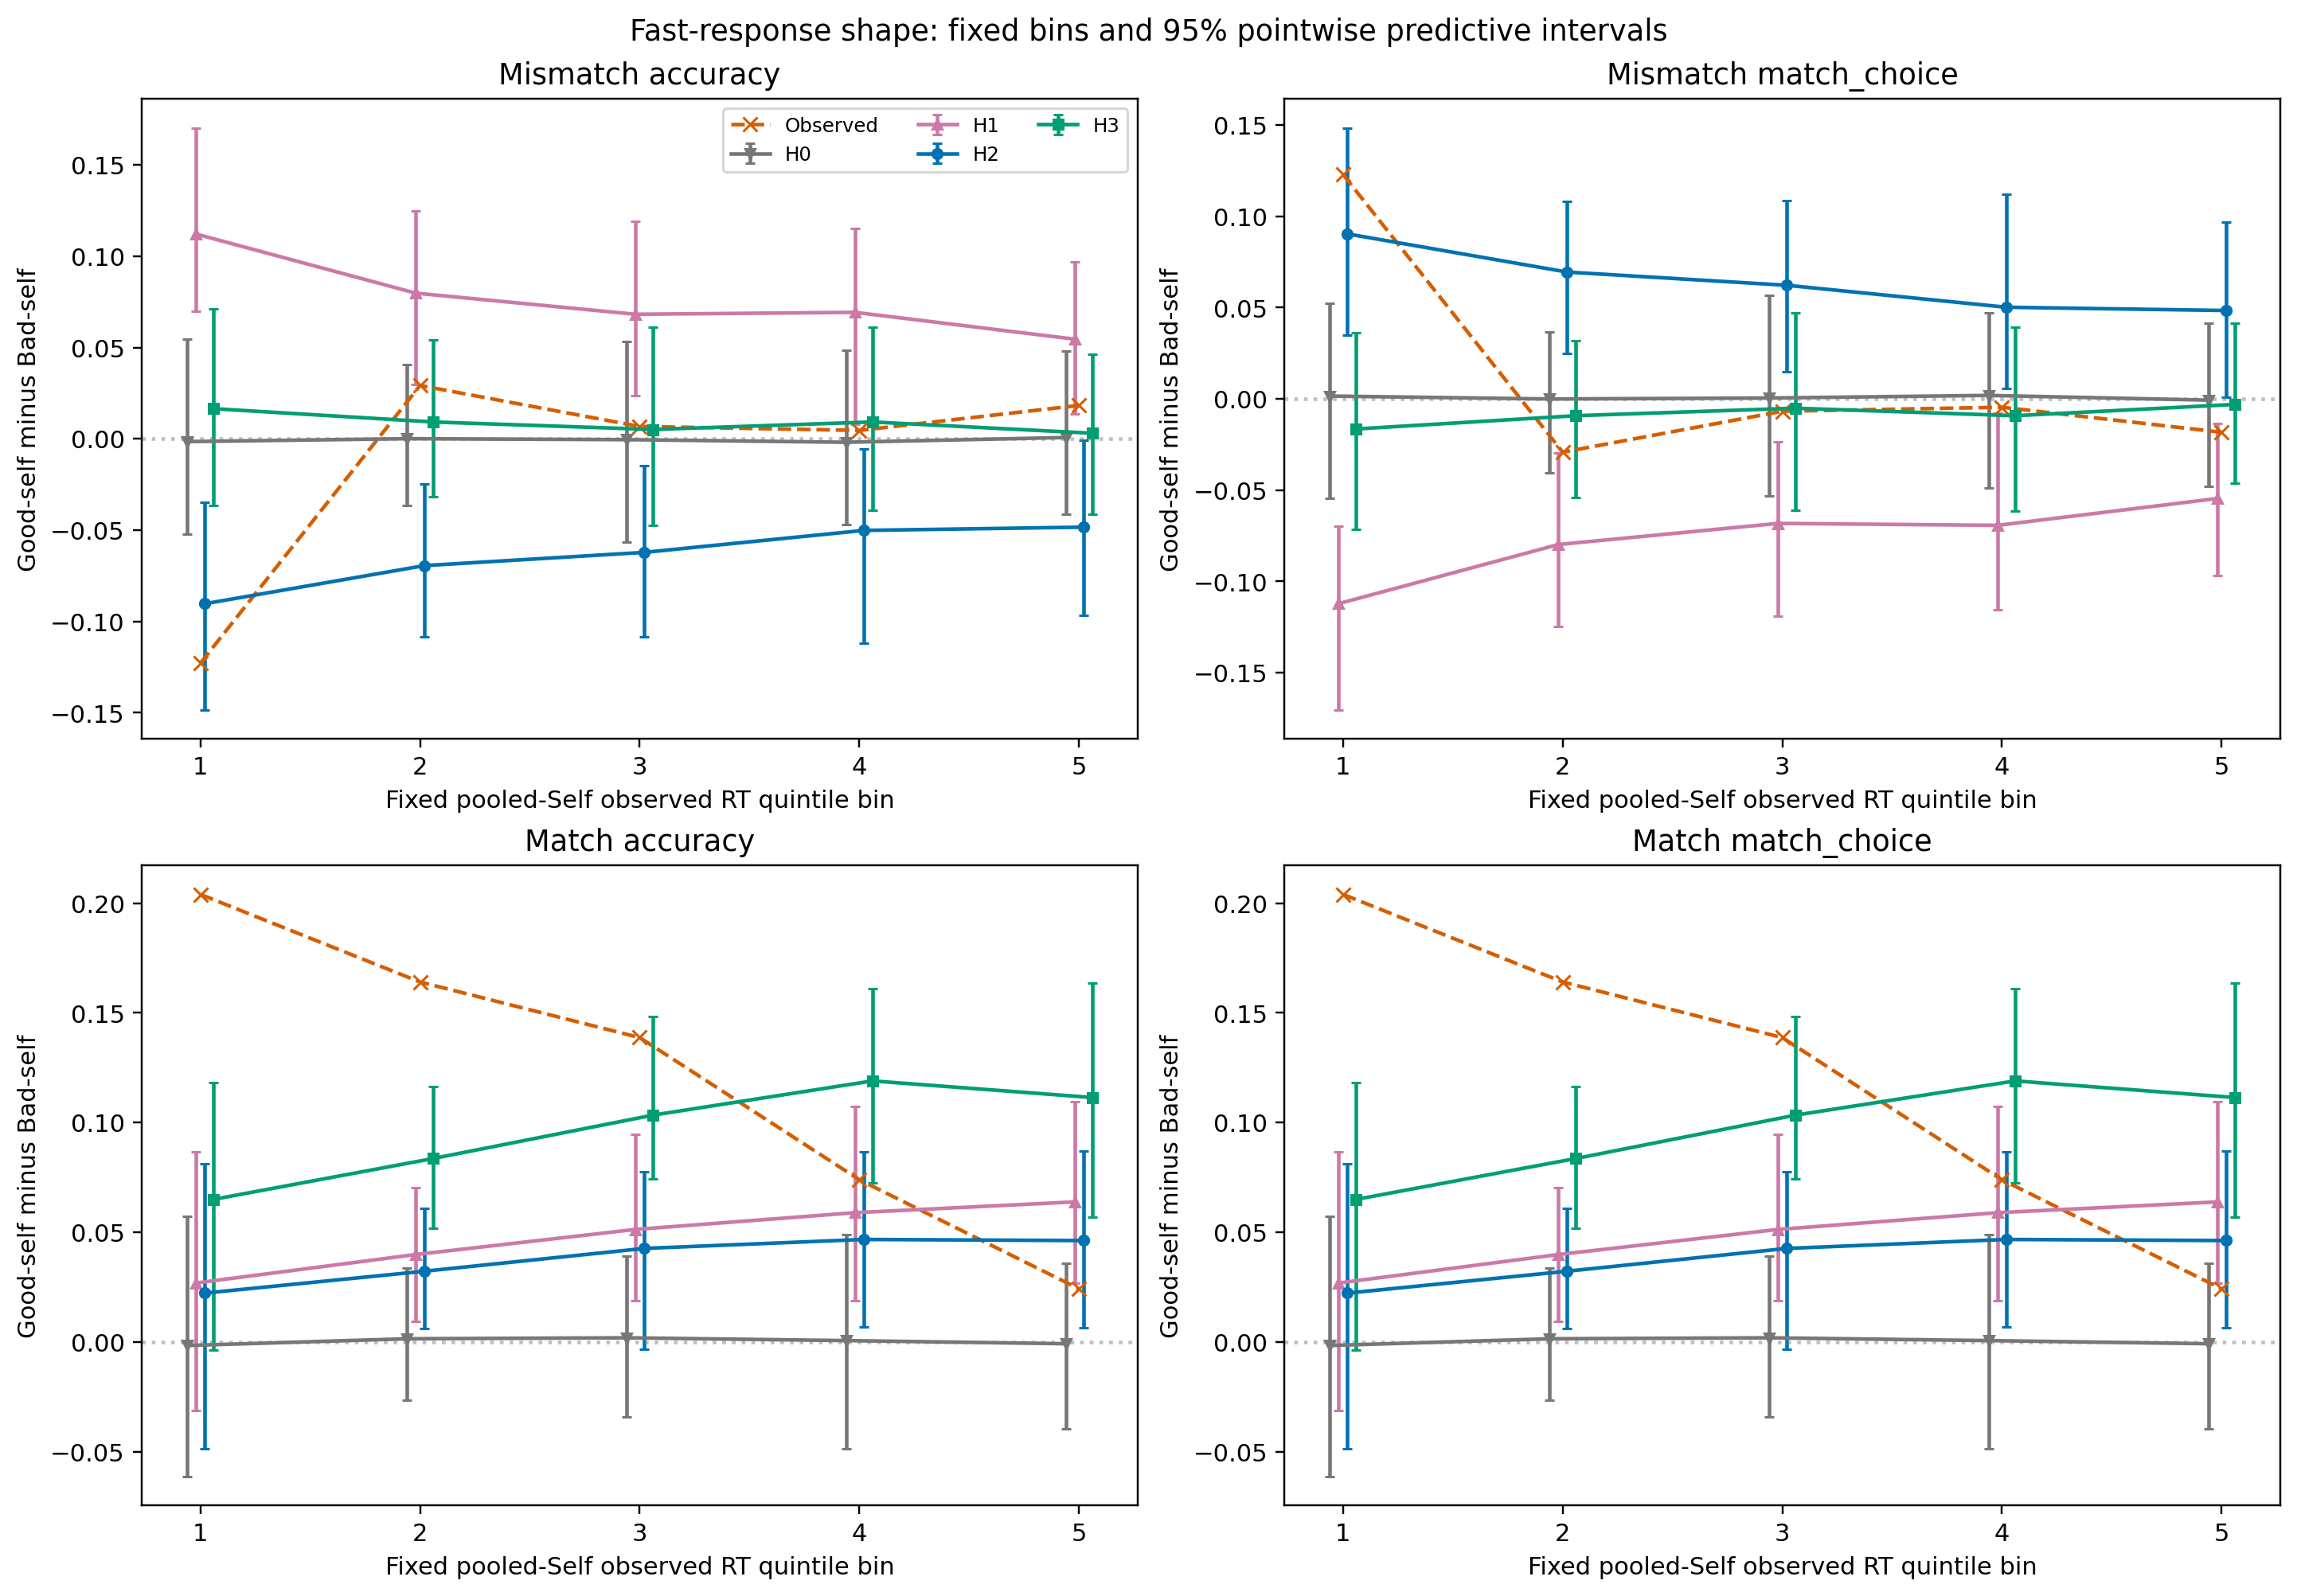

,model,group,metric,observed,median,lower,upper,observed_in_95_predictive_interval
20,H0,Self|stim=0,fast_accuracy_good_minus_bad,-0.12285,-0.00154,-0.05240,0.05467,False
21,H1,Self|stim=0,fast_accuracy_good_minus_bad,-0.12285,0.11214,0.06975,0.17031,False
22,H2,Self|stim=0,fast_accuracy_good_minus_bad,-0.12285,-0.09032,-0.14843,-0.03492,True
23,H3,Self|stim=0,fast_accuracy_good_minus_bad,-0.12285,0.01649,-0.03636,0.07138,False
24,H0,Self|stim=1,fast_accuracy_good_minus_bad,0.20401,-0.00161,-0.06130,0.05744,False
25,H1,Self|stim=1,fast_accuracy_good_minus_bad,0.20401,0.02689,-0.03141,0.08684,False
26,H2,Self|stim=1,fast_accuracy_good_minus_bad,0.20401,0.02228,-0.04883,0.08121,False
27,H3,Self|stim=1,fast_accuracy_good_minus_bad,0.20401,0.06500,-0.00373,0.11836,False


In [10]:
show('02_reanalysis_2026/Output/hddm/matching/continuation_stage4_20261027/four_model_ppc/four_model_fast_shape_ppc.png')
key_ppc=table('02_reanalysis_2026/Output/hddm/matching/continuation_stage5_20261027/key_ppc_results.csv')
display(key_ppc[key_ppc.metric.eq('fast_accuracy_good_minus_bad')])

## 预测比较：尚未完成

原 PSIS 各模型都有高 k 事件，不以未修正分数排名。第一轮五折×四模型共20套训练短链均失败；修复仅 H2 fold4 通过，H0 fold4 仍有 R̂=1.013752、tail ESS=63.26。`fold4` 是第五折，不是新模型 H4；也不存在“五十个比较已修复”的结论。

不能从唯一成功的一套生成四模型 ΔELPD 图。即使完成，截止代理仍来自完整记录，预测目标只是给定代理、已有被试的留出事件，不是独立前瞻或新被试预测。

In [11]:
display(table('02_reanalysis_2026/Output/hddm/matching/continuation_stage5_20261027/initial_kfold_diagnostics.csv'))
rows=[]
for fit in ['H0_fold4','H2_fold4']:
    status=json.loads((ROOT/'02_reanalysis_2026/Output/hddm/matching/continuation_stage5_20261027/kfold5_repair'/fit/'status.json').read_text())
    rows.append(dict(fit=fit,status=status['status'],**status['diagnostics']))
display(pd.DataFrame(rows)[['fit','status','max_rhat','min_bulk_ess','min_tail_ess']])

,fit,status,max_rhat,bulk,tail
0,H0_fold0,short_diagnostics_failed,1.06828,54.13580,137.23954
1,H0_fold1,short_diagnostics_failed,1.04139,84.73718,102.67022
2,H0_fold2,short_diagnostics_failed,1.02664,278.00460,261.33665
3,H0_fold3,short_diagnostics_failed,1.02190,229.77425,300.51022
4,H0_fold4,short_diagnostics_failed,1.36585,9.02400,31.78822
5,H1_fold0,short_diagnostics_failed,1.06255,64.31574,94.64461
6,H1_fold1,short_diagnostics_failed,1.05262,54.98506,116.12472
7,H1_fold2,short_diagnostics_failed,1.02619,302.93341,245.26865
8,H1_fold3,short_diagnostics_failed,1.03113,157.40429,196.32894
9,H1_fold4,short_diagnostics_failed,1.03100,101.34904,213.52903


,fit,status,max_rhat,min_bulk_ess,min_tail_ess
0,H0_fold4,short_diagnostics_failed,1.01375,378.15207,63.25653
1,H2_fold4,complete,1.00304,1662.22885,2216.44963


## 敏感性、限制与下一步

污染 RT 上界 2→1.5 秒：H3 直接重拟合通过，两目标方向保持；H2 短诊断 tail ESS=210.63 不足。新上界 H3 PPC 尚未生成。该扰动下稳定不意味着模型充分；dc 的数值/心理含义仍依赖难度参照。

下一步需完成逐折诊断与预测、模型差异的不确定性汇总，以及剩余敏感性和观察规则核查。目前不能宣称 H2 推翻原论文 v 解释，也不能宣布 H3 唯一胜出。**第三部分尚未正式分析；后续计划不能冒充已执行结果。**

In [12]:
rows=[]
for model in ['H2','H3']:
    status=json.loads((ROOT/'02_reanalysis_2026/Output/hddm/matching/continuation_stage5_20261027/support_refits'/model/'status.json').read_text())
    rows.append(dict(model=model,status=status['status'],**status['diagnostics']))
display(pd.DataFrame(rows)[['model','status','max_rhat','min_bulk_ess','min_tail_ess']])
display(table('02_reanalysis_2026/Output/hddm/matching/continuation_stage5_20261027/support_refits/H3/baseline_vs_support_posterior.csv'))

,model,status,max_rhat,min_bulk_ess,min_tail_ess
0,H2,short_diagnostics_failed,1.00564,829.10748,210.63275
1,H3,complete,1.00235,2878.88884,2523.98677


,target,parameter,mean,median,lower,upper,fixed_zero
0,original_upper_2,mean_beta_v,0.38500,0.38523,0.26240,0.50586,False
1,original_upper_2,mean_beta_dc,0.63742,0.63795,0.47673,0.79828,False
2,original_upper_2,contamination,0.04701,0.04696,0.04315,0.05100,False
3,refitted_upper_1.5,mean_beta_v,0.38603,0.38586,0.26246,0.50990,False
4,refitted_upper_1.5,mean_beta_dc,0.66397,0.66458,0.49792,0.82786,False
5,refitted_upper_1.5,contamination,0.06256,0.06250,0.05768,0.06762,False


## 复现与溯源

本 Notebook 的执行只重读已存图表，不能代替重新生成后验和 PPC。原始证据保留在 Output 的阶段目录；[证据清单](docs/evidence_manifest.json)含发布文件的 SHA-256，[验证记录](docs/VALIDATION.md)区分已执行展示与未重跑采样。完整后验与大型中间文件仅本机保存。
